# 9장 G U I 프로그래밍

### 학습목표
- tkinter를 이용하여 간단한 GUI 프로그램을 작성할 수 있다.
- GUI의 일반적인 구조를 이해할 수 있다.
- 배치 관리자를 사용할 수 있다.
- 위젯의 콜백 함수를 이용하여 이벤트를 처리할 수 있다.
- 캔버스에 다양한 도형을 그릴 수 있다.
- 애니메이션을 만들 수 있다. 

# Tkinter의 위젯들
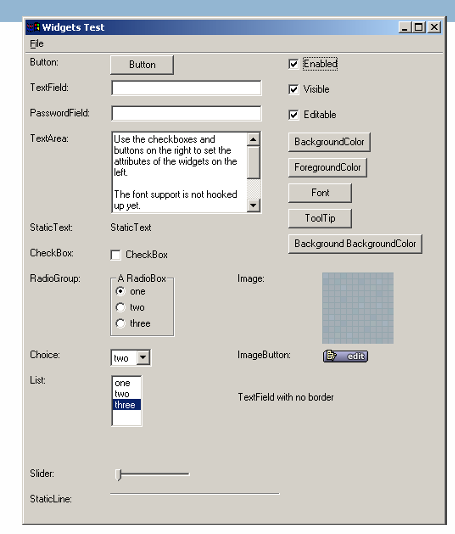
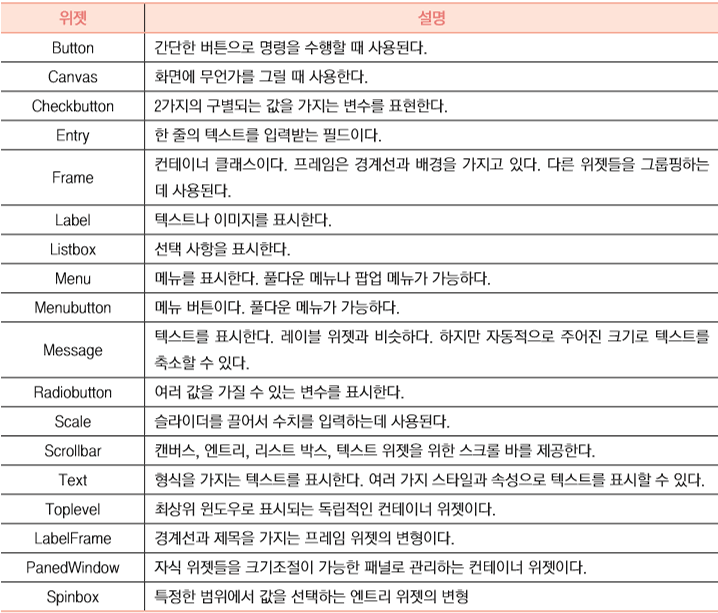

In [2]:
import tkinter as tk
from tkinter import ttk, messagebox

# 버튼 클릭 시 호출되는 콜백: 눌린 버튼의 이름을 메시지 박스로 보여 줍니다.
def on_button_click(name):
    messagebox.showinfo("알림", f"'{name}' 버튼이 눌렸습니다.")

# 1. 메인 윈도우 설정
root = tk.Tk()
root.title("Widgets Test")
root.geometry("620x720")
root.configure(bg="#CECAD3") # 클래식 윈도우 회색 배경

# --- 메뉴바 (Menu) ---
menubar = tk.Menu(root)
filemenu = tk.Menu(menubar, tearoff=0)
filemenu.add_command(label="Exit", command=root.quit)
menubar.add_cascade(label="File", menu=filemenu)
root.config(menu=menubar)

# 전체적인 패딩 스타일 정의
pad_opts = {'padx': 10, 'pady': 6}

# --- 1행: Button & Checkboxes ---
lbl_button = tk.Label(root, text="Button:", bg="#D4D0C8", anchor="w")
lbl_button.grid(row=0, column=0, sticky="w", **pad_opts)

# command에 lambda를 써서 이 버튼의 이름을 콜백에 전달합니다.
btn_sample = tk.Button(root, text="Button", width=12, relief="raised", command=lambda: on_button_click("Button"))
btn_sample.grid(row=0, column=1, sticky="w", **pad_opts)

# 우측 체크박스 그룹용 프레임
chk_frame = tk.Frame(root, bg="#D4D0C8")
chk_frame.grid(row=0, column=2, rowspan=3, sticky="nw", padx=30, pady=5)

chk_enabled = tk.Checkbutton(chk_frame, text="Enabled", bg="#D4D0C8")
chk_enabled.select() # 체크 활성화
chk_enabled.pack(anchor="w", pady=2)

chk_visible = tk.Checkbutton(chk_frame, text="Visible", bg="#D4D0C8")
chk_visible.select()
chk_visible.pack(anchor="w", pady=2)

chk_editable = tk.Checkbutton(chk_frame, text="Editable", bg="#D4D0C8")
chk_editable.select()
chk_editable.pack(anchor="w", pady=2)

# --- 2행: TextField ---
lbl_textfield = tk.Label(root, text="TextField:", bg="#D4D0C8", anchor="w")
lbl_textfield.grid(row=1, column=0, sticky="w", **pad_opts)

entry_text = tk.Entry(root, width=30, relief="sunken")
entry_text.grid(row=1, column=1, sticky="w", **pad_opts)

def on_enter(event=None):
    # Enter 키를 누르면 입력된 값을 읽어 메시지 박스로 보여 줍니다.
    messagebox.showinfo("입력값", f"입력된 값: {entry_text.get()}")

entry_text.bind("<Return>", on_enter)
'''
Entry 위젯의 콜백함수 : bind("<Return>", 콜백함수) 처럼 연결
-def on_click(event):
    print("클릭 위치:", event.x, event.y)      # 위젯 내부 좌표
    print("화면 좌표:", event.x_root, event.y_root)
    print("현재 값:", event.widget.get())

entry_text.bind("<Button-1>", on_click)          # 왼쪽 버튼 누름
entry_text.bind("<ButtonRelease-1>", on_release) # 왼쪽 버튼 뗌
entry_text.bind("<Double-Button-1>", on_double)  # 왼쪽 더블클릭
entry_text.bind("<Button-3>", on_right)          # 오른쪽 클릭 (macOS는 Button-2)
entry_text.bind("<B1-Motion>", on_drag)          # 왼쪽 버튼을 누른 채 드래그
entry_text.bind("<MouseWheel>", on_wheel)        # 휠 (Windows: event.delta)
entry_text.bind("<Enter>", on_mouse_in)          # 마우스가 위젯 위로 들어옴
entry_text.bind("<Leave>", on_mouse_out)         # 마우스가 위젯을 벗어남
entry_text.bind("<FocusIn>", on_focus_in)        # 포커스를 얻음 (클릭/Tab)
entry_text.bind("<FocusOut>", on_focus_out)      # 포커스를 잃음
'''

# --- 3행: PasswordField ---
lbl_password = tk.Label(root, text="PasswordField:", bg="#D4D0C8", anchor="w")
lbl_password.grid(row=2, column=0, sticky="w", **pad_opts)

entry_pass = tk.Entry(root, width=30, show="*", relief="sunken")
entry_pass.grid(row=2, column=1, sticky="w", **pad_opts)

# --- 4행: TextArea & 속성 버튼들 ---
lbl_textarea = tk.Label(root, text="TextArea:", bg="#D4D0C8", anchor="w")
lbl_textarea.grid(row=3, column=0, sticky="nw", **pad_opts)

# 스크롤바가 포함된 텍스트 영역
txt_frame = tk.Frame(root)
txt_frame.grid(row=3, column=1, sticky="w", **pad_opts)

scrollbar = tk.Scrollbar(txt_frame)
scrollbar.pack(side="right", fill="y")

text_area = tk.Text(txt_frame, width=28, height=7, relief="sunken", yscrollcommand=scrollbar.set)
text_area.insert("1.0", "Use the checkboxes and\nbuttons on the right to set the\nattributes of the widgets on the\nleft.\n\nThe font support is not hooked\nup yet.")
text_area.pack(side="left", fill="both")
scrollbar.config(command=text_area.yview)

# 우측 속성 제어 버튼들
btn_frame = tk.Frame(root, bg="#D4D0C8")
btn_frame.grid(row=3, column=2, sticky="nw", padx=30, pady=5)

buttons = ["BackgroundColor", "ForegroundColor", "Font", "ToolTip", "Background BackgroundColor"]
for btn_text in buttons:
    # t=btn_text 기본값으로 현재 반복의 이름을 고정해야 모든 버튼이 마지막 이름을 보여 주는 문제를 피합니다.
    b = tk.Button(btn_frame, text=btn_text, width=22, relief="raised", command=lambda t=btn_text: on_button_click(t))
    b.pack(pady=3, anchor="w")

# --- 5행: StaticText ---
lbl_static_lbl = tk.Label(root, text="StaticText:", bg="#D4D0C8", anchor="w")
lbl_static_lbl.grid(row=4, column=0, sticky="w", **pad_opts)

lbl_static_val = tk.Label(root, text="StaticText", bg="#D4D0C8")
lbl_static_val.grid(row=4, column=1, sticky="w", **pad_opts)

# --- 6행: CheckBox ---
lbl_checkbox_lbl = tk.Label(root, text="CheckBox:", bg="#D4D0C8", anchor="w")
lbl_checkbox_lbl.grid(row=5, column=0, sticky="w", **pad_opts)

chk_sample = tk.Checkbutton(root, text="CheckBox", bg="#D4D0C8")
chk_sample.grid(row=5, column=1, sticky="w", **pad_opts)

# --- 7행: RadioGroup & Image 영역 ---
lbl_radiogroup = tk.Label(root, text="RadioGroup:", bg="#D4D0C8", anchor="w")
lbl_radiogroup.grid(row=6, column=0, sticky="nw", **pad_opts)

# 테두리가 있는 라디오박스 프레임
radio_frame = tk.LabelFrame(root, text="A RadioBox", bg="#D4D0C8", padx=10, pady=5)
radio_frame.grid(row=6, column=1, sticky="w", **pad_opts)

radio_var = tk.StringVar(value="one")
r1 = tk.Radiobutton(radio_frame, text="one", value="one", variable=radio_var, bg="#D4D0C8")
r2 = tk.Radiobutton(radio_frame, text="two", value="two", variable=radio_var, bg="#D4D0C8")
r3 = tk.Radiobutton(radio_frame, text="three", value="three", variable=radio_var, bg="#D4D0C8")
r1.pack(anchor="w")
r2.pack(anchor="w")
r3.pack(anchor="w")

# 우측 Image 캔버스 영역
lbl_image = tk.Label(root, text="Image:", bg="#D4D0C8")
lbl_image.grid(row=6, column=2, sticky="nw", padx=30, pady=5)

# 격자 무늬 배경의 더미 이미지 공간 (Canvas 사용)
canvas_img = tk.Canvas(root, width=100, height=100, bg="#A0B0C0", highlightthickness=1, highlightbackground="gray")
canvas_img.grid(row=6, column=2, sticky="nw", padx=90, pady=5)
# 모눈종이 같은 격자선 그리기
for i in range(0, 100, 10):
    canvas_img.create_line(i, 0, i, 100, fill="#B0C0D0")
    canvas_img.create_line(0, i, 100, i, fill="#B0C0D0")

# --- 8행: Choice & ImageButton ---
lbl_choice = tk.Label(root, text="Choice:", bg="#D4D0C8", anchor="w")
lbl_choice.grid(row=7, column=0, sticky="w", **pad_opts)

# Choice에 대응하는 ttk.Combobox
combo_choice = ttk.Combobox(root, values=["one", "two", "three"], width=8, state="readonly")
combo_choice.set("two")
combo_choice.grid(row=7, column=1, sticky="w", **pad_opts)

lbl_imgbtn = tk.Label(root, text="ImageButton:", bg="#D4D0C8")
lbl_imgbtn.grid(row=7, column=2, sticky="w", padx=30, pady=5)

# 저장해 둔 PNG 아이콘(노트북과 같은 폴더)을 불러옵니다.
edit_icon = tk.PhotoImage(file="edit_icon.png")
# image로 아이콘을 넣고 compound="left"로 아이콘을 글자 왼쪽에 놓습니다.
# 이미지를 쓰면 width는 글자 수가 아니라 픽셀 단위입니다.
btn_edit = tk.Button(root, text=" edit", image=edit_icon, compound="left", width=80, bg="#6A6A9B", fg="white", relief="raised", command=lambda: on_button_click("edit"))
btn_edit.image = edit_icon  # 이미지 객체가 가비지 컬렉션으로 사라지지 않도록 참조를 유지합니다.
btn_edit.grid(row=7, column=2, sticky="w", padx=120, pady=5)

# --- 9행: List & Borderless TextField ---
lbl_list = tk.Label(root, text="List:", bg="#D4D0C8", anchor="w")
lbl_list.grid(row=8, column=0, sticky="nw", **pad_opts)

listbox = tk.Listbox(root, width=10, height=4, relief="sunken")
for item in ["one", "two", "three"]:
    listbox.insert("end", item)
listbox.select_set(2) # 'three' 선택 상태로 만들기
listbox.grid(row=8, column=1, sticky="w", **pad_opts)

lbl_noborder = tk.Label(root, text="TextField with no border", bg="#D4D0C8")
lbl_noborder.grid(row=8, column=2, sticky="nw", padx=30, pady=5)

# --- 10행: Slider (Scale) ---
lbl_slider = tk.Label(root, text="Slider:", bg="#D4D0C8", anchor="w")
lbl_slider.grid(row=9, column=0, sticky="w", **pad_opts)

slider = tk.Scale(root, from_=0, to=100, orient="horizontal", showvalue=False, width=10, length=200, bg="#D4D0C8", bd=1)
slider.set(20)
slider.grid(row=9, column=1, columnspan=2, sticky="w", **pad_opts)

# 슬라이더 위에 현재 위치(%)를 보여 주는 라벨
lbl_percent = tk.Label(root, bg="#D4D0C8", fg="#333333", font=("맑은 고딕", 8, "bold"))

def on_slide(value=None):
    # Scale의 command는 값을 문자열로 넘겨주므로 직접 읽어 씁니다.
    v = slider.get()
    percent = (v - slider.cget("from")) / (slider.cget("to") - slider.cget("from")) * 100
    lbl_percent.config(text=f"{percent:.0f}%")
    # coords()는 현재 값에 해당하는 손잡이 중심 좌표(슬라이더 기준)를 돌려줍니다.
    x, _ = slider.coords(v)
    lbl_percent.place(x=slider.winfo_x() + x, y=slider.winfo_y() - 2, anchor="s")

slider.config(command=on_slide)
root.update_idletasks()  # 위젯 위치가 확정된 뒤에
on_slide()               # 초기값(20%)을 표시합니다.

# --- 11행: StaticLine ---
lbl_line = tk.Label(root, text="StaticLine:", bg="#D4D0C8", anchor="w")
lbl_line.grid(row=10, column=0, sticky="w", **pad_opts)

# 구분선 구현 (두께 2픽셀의 프레임)
sep_line = tk.Frame(root, height=2, bd=1, relief="sunken", bg="gray")
sep_line.grid(row=10, column=1, columnspan=2, sticky="we", padx=10, pady=10)

# --- 클릭 시 위젯 이름을 풍선말로 표시 ---
# 변수 이름으로 위젯을 찾을 수 있도록 {위젯 경로: 변수 이름} 사전을 만듭니다.
var_names = {str(v): k for k, v in list(globals().items()) if isinstance(v, tk.Widget)}
tip = {'win': None, 'job': None}  # 현재 떠 있는 풍선과 자동 닫기 예약을 저장합니다.

def hide_tip():
    if tip['job']:
        root.after_cancel(tip['job'])  # 예약된 닫기 작업을 취소합니다.
        tip['job'] = None
    if tip['win']:
        tip['win'].destroy()  # 기존 풍선을 제거합니다.
        tip['win'] = None

def show_tip(event):
    w = event.widget
    name = var_names.get(str(w), w.winfo_class())  # 변수 이름, 없으면 위젯 종류
    if 'text' in w.keys() and w.cget('text'):
        name += f" ({w.cget('text')})"  # 버튼·라벨 등은 표시 글자도 함께 보여 줍니다.
    hide_tip()
    win = tk.Toplevel(root)
    win.wm_overrideredirect(True)  # 제목 표시줄 없는 풍선 창으로 만듭니다.
    win.wm_geometry(f"+{event.x_root + 12}+{event.y_root + 12}")  # 마우스 오른쪽 아래에 표시합니다.
    tk.Label(win, text=name, bg="#FFFFE0", relief="solid", bd=1, padx=6, pady=2).pack()
    tip['win'] = win
    tip['job'] = root.after(1500, hide_tip)  # 1.5초 뒤 자동으로 사라집니다.

def bind_tips(widget):
    widget.bind('<Button-1>', show_tip, add='+')  # add='+'로 기존 클릭 동작을 유지합니다.
    for child in widget.winfo_children():
        bind_tips(child)  # 프레임 안의 위젯까지 재귀적으로 연결합니다.

for child in root.winfo_children():
    bind_tips(child)

# 메인 루프 실행
root.mainloop()

TclError: couldn't open "edit_icon.png": no such file or directory

# 배치와 옵션 해설
- rid(row, column): 위젯을 행과 열로 이루어진 격자에 배치합니다.
- pack(...): 위젯을 컨테이너 안에 순서대로 쌓아 배치합니다.
- sticky="w" / sticky="nw": 격자 셀 안에서 왼쪽 / 왼쪽 위에 붙입니다.
- rowspan / columnspan: 위젯이 차지할 행 / 열의 개수를 지정합니다.
- padx / pady: 위젯 주변의 가로 / 세로 여백입니다.